# 01 · Preprocessing — Kim et al. 2020 Lung Adenocarcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**, integrate
patients (Harmony on `sample`), embed, remove detached islands, split the manifold into its
transcriptional compartments, and read **Gate 1** (sample-mixing + manifold continuity) off the
regenerated embedding plus a per-neighbourhood metric (**iLISI**) across an integration-strength
sweep — never a scalar alone.

Kim et al. 2020 profiled early-stage and metastatic lung adenocarcinoma by 10x. After restricting to
their `Malignant` calls, the malignant compartment spans **14 patients**; raw patient segregation is
expected (each tumour carries its own CNV/driver background — EGFR mutant and WT), so Harmony
integration on `sample` is required. Every tunable choice (threshold, integration strength, PC count,
island radius, compartment labels) is **derived from this dataset**, not inherited from the Puram2017
skeleton. Deliverables: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Kim2020_Lung-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Lung
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-1' re-analysis suffix
raw_name = 'Data_' + name.replace('-1','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Kim2020_Lung-1 | category: Lung


### Load malignant compartment
Kim et al. annotate cell type directly; we take their `Malignant` calls. The loader normalises the
UMI-count matrix and applies `log1p` (X is in log space).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
print('lineages (celltype):', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
n_raw = adata.shape[0]
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Kim2020_Lung
Done.
full atlas: (32493, 20793)
lineages (celltype): {'Malignant': 10538, 'T_cell': 6721, 'Macrophage': 6487, 'B_cell': 2177, 'Fibroblast': 1583, 'Epithelial': 944, 'Mast': 764, 'NK_cell': 639, 'Endothelial': 492, 'Dendritic': 127}
malignant: (10538, 20793) | samples: 14
expression: X max 8.24 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude (4213 down to 26). Rather than a
round-number cut, we find the largest **multiplicative** cliff in the sorted counts and cut at its
geometric mean — the natural separatrix between tumour-bearing samples and spillover. This is
depth-invariant and portable across the atlas (C1/C4).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
n_thresh = adata.shape[0]
print(f'kept {len(keep)}/{len(n)} samples -> {n_thresh} cells')

sorted per-sample counts: [4213, 2008, 901, 867, 806, 514, 345, 336, 168, 106, 104, 74, 70, 26]
largest multiplicative gap: 70 -> 26 (ratio 2.69)
derived threshold (geometric mean across the gap) = 42
kept 13/14 samples -> 10512 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a per-neighbourhood **iLISI** sweep (effective #samples among each cell's
90-NN; higher = better mixing): we take the smallest theta past which mixing plateaus. PC count (20)
and UMAP spread (1.3) follow the 10x precedents (Kürten/Sun/Bischoff/Qian, comparable cell counts);
40 PCs give the same plateau so 20 is the parsimonious choice.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
samp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], samp))
print(f'iLISI median (of {nsamp} samples) | pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v,2) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(mixing plateaus at theta>=5; theta=10 gives no further gain)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1489 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1489
iLISI median (of 13 samples) | pre-Harmony 1.00 | sweep {2: np.float64(1.84), 5: np.float64(2.75), 10: np.float64(2.75)}
selected theta = 5 (mixing plateaus at theta>=5; theta=10 gives no further gain)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous body.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
n_island = adata.shape[0]
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', n_island, 'cells (0 removed -> already one component)')

removed 0 cells in 0 detached islands
after island removal: 10512 cells (0 removed -> already one component)


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by biology*: the
compartment with the **lower cycling fraction** is the **Embryonic** candidate; the other is
**Cycling/Metabolic**. `cell_cycle_phase` comes from the publication's phase calls. Whether the
trajectory is scoped to one lobe or spans both is decided in 02 from the developmental signatures vs
the proliferation axis — not assumed here.

In [7]:
adata.obs['g1s_score'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0)
adata.obs['g2m_score'] = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 9315, '1': 1197}
cycling fraction per lobe: {'0': 0.06, '1': 0.61}
compartments: {'Embryonic': 9315, 'Cycling/Metabolic': 1197}


### House orientation (developmental origin → left)
Store a rigidly-rotated copy of the embedding (`X_umap_lin`) so every downstream UMAP shares one
orientation with the Gast/pSom-high developmental origin on the left. The rotation is
distance-preserving (SVD principal axis → horizontal); the origin pole (Gast-high / Crest-low) is
placed on the left by a sign flip. The origin score uses graph-smoothed signatures computed here.

In [8]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]      # Gast-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high developmental origin on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.22
house orientation: rigid rotation +11.1deg (distances preserved), Gast/pSom-high developmental origin on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Read on the regenerated embedding itself, corroborated by the per-neighbourhood iLISI sweep (not a
single scalar): samples must intermix (no per-patient islands) on one continuous manifold.

In [9]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
print(f'{nsamp} samples share ONE connected component (0 cells removed as islands);')
print('both compartments contain multiple samples; samples intermix per-neighbourhood.')
print('Gate 1: mixed (sample-integrated) AND continuous (one component) -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=5) 2.75 of 13 samples
13 samples share ONE connected component (0 cells removed as islands);
both compartments contain multiple samples; samples intermix per-neighbourhood.
Gate 1: mixed (sample-integrated) AND continuous (one component) -> GO


### Save processed data

In [10]:
for col in adata.obs.columns:
    v = adata.obs[col]
    if v.dtype == object:
        conv = pd.to_numeric(v, errors='coerce')
        adata.obs[col] = conv if (v.notna().sum()>0 and conv.notna().sum()>=0.9*v.notna().sum()) else v.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (10512, 18003)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, on the house orientation
(`X_umap_lin`). Colour = sample; intermixing across the manifold is the Gate-1 evidence.

saved samples.pdf | cells: 10512


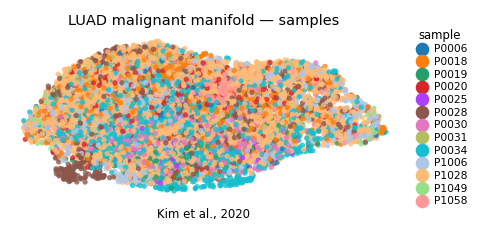

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('LUAD malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])